# Import Libraries

In [1]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

# Download Financial Data

Download 5 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [2]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='5y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

/Users/sakis/projects/msc_dws/101-MachineLearning/02-KNN-TimeseriesForecasting/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/sakis/projects/msc_dws/101-MachineLearning/02-KNN-TimeseriesForecasting/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/sakis/projects/msc_dws/101-MachineLearning/02-KNN-TimeseriesForecasting/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future vers

,Date,Open,High,Low,Close
0,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997
1,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996
2,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001
3,2021-11-04 00:00:00-04:00,93.860001,94.470001,93.830002,94.349998
4,2021-11-05 00:00:00-04:00,94.339996,94.620003,94.190002,94.320000
...,...,...,...,...,...
1252,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
1253,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
1254,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002
1255,2026-10-29 00:00:00-04:00,102.080002,102.449997,101.849998,102.040001


# Construct Line Plot of HLC Data

In [3]:
df.describe()

,Open,High,Low,Close
count,1257.000000,1257.000000,1257.000000,1257.000000
mean,102.267749,102.600398,101.945545,102.280159
std,3.796377,3.850099,3.730509,3.793623
min,93.860001,94.129997,93.820000,93.860001
25%,99.129997,99.410004,98.879997,99.169998
50%,102.300003,102.629997,101.989998,102.300003
75%,104.620003,105.010002,104.260002,104.669998
max,114.190002,114.779999,113.330002,114.110001


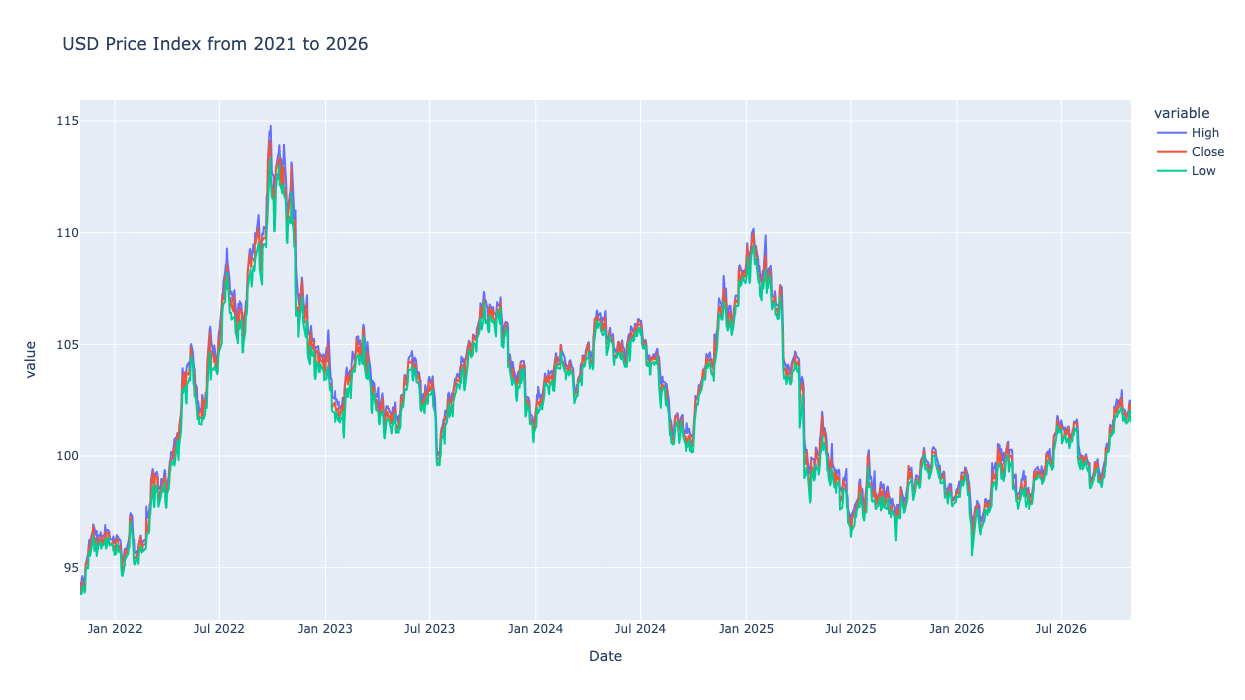

In [4]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2021 to 2026')
fig.update_layout(width=1200, height=700)
fig.show()

In [5]:
# Οπτικά και μόνο, φαίνεται ότι μπορούν οι συγκεκριμένες χρονοσειρές να είναι στάσιμες, καθώς μπορεί να πει κανείς πως παρά
# τις μεγάλες διακυμάνσεις υπάρχει μια μέση τιμή κοντά γύρω στο 102-103 η οποία διατηρείται στο διάστημα που παρατηρούμε

In [6]:
from statsmodels.tsa.stattools import adfuller, kpss

results = {}
for ts in ["High", "Low", "Close"]:
    for i, f in enumerate([adfuller, kpss]):
        res = f(df[ts].dropna(), result_object=True)
        if ts not in results:
            results[ts] = {}
        results[ts][f.__name__] = res

limit = 0.05
for k, v in results.items():
    if any([
        v["adfuller"].pvalue >= limit,
        v["kpss"].pvalue < limit,
    ]):
        print(f"{k} is not stationary")

High is not stationary
Low is not stationary
Close is not stationary


/var/folders/r9/2w6rqz494j16pn5w9gcnvfrm0000gn/T/ipykernel_4602/4123691797.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  res = f(df[ts].dropna(), result_object=True)
/var/folders/r9/2w6rqz494j16pn5w9gcnvfrm0000gn/T/ipykernel_4602/4123691797.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  res = f(df[ts].dropna(), result_object=True)
/var/folders/r9/2w6rqz494j16pn5w9gcnvfrm0000gn/T/ipykernel_4602/4123691797.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  res = f(df[ts].dropna(), result_object=True)


# Train-Test Split

Test set should start 1 time step after the end of train set.

In [7]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((879, 5), (408, 5))

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [8]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [9]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997
1,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996
2,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001
3,2021-11-04 00:00:00-04:00,93.860001,94.470001,93.830002,94.349998
4,2021-11-05 00:00:00-04:00,94.339996,94.620003,94.190002,94.320000


In [10]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [94.12999725 94.30999756 93.86000061 93.87999725 93.93000031 94.12999725
 93.81999969 94.08999634 94.12000275 94.20999908 93.81999969 93.86000061
 93.86000061 94.47000122 93.83000183 94.34999847] 
y: 94.31999969482422


# Fit Linear Regression Model

Setting H = 30

In [11]:
x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((849, 120), (849,), (378, 120), (378,))

Training for history_size=1
train mae: 0.370105030470895 - test mae: 0.30088121716836913
Training for history_size=5
train mae: 0.3672661932390618 - test mae: 0.30390483045018746
Training for history_size=15
train mae: 0.3608476768585227 - test mae: 0.30382868619214587
Training for history_size=30
train mae: 0.3531580622374581 - test mae: 0.3198908135157699


<Axes: title={'center': 'Train-Test MAE of Linear Regression per window size H'}, xlabel='Window size H (days)', ylabel='MAE'>

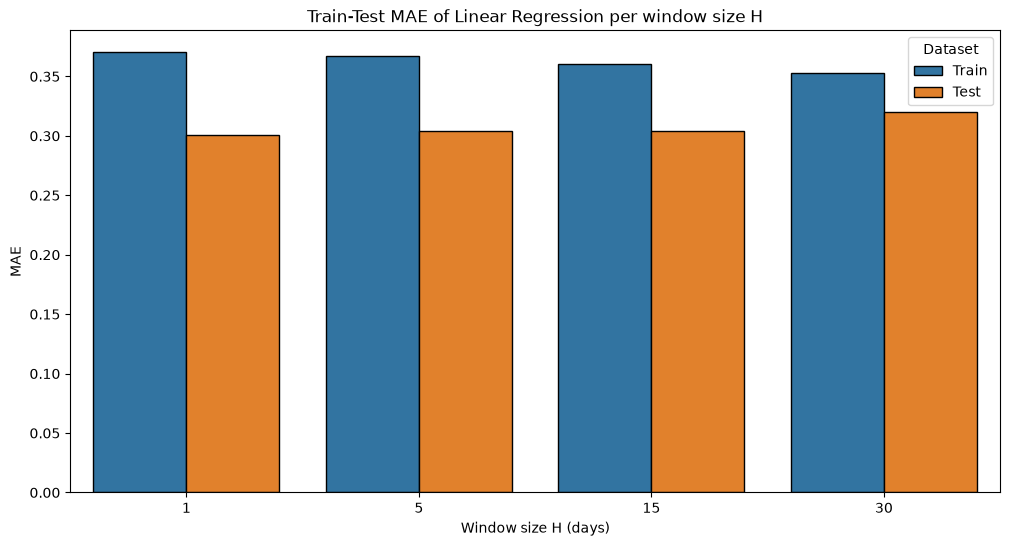

In [12]:
rows = []
for history_size in [1, 5, 15, 30]:
    print(f"Training for history_size={history_size}")
    x_train, y_train = construct_timeframes(train_df, history_size)
    x_test, y_test = construct_timeframes(test_df, history_size)
    model = LinearRegression()
    model.fit(x_train, y_train)

    y_pred = model.predict(x_train)
    train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred)
    y_pred = model.predict(x_test)
    test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)

    print(f"train mae: {train_mae} - test mae: {test_mae}")
    rows.append({"H": history_size, "Dataset": "Train", "MAE": train_mae})
    rows.append({"H": history_size, "Dataset": "Test", "MAE": test_mae})

metrics_df = pd.DataFrame(rows)
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=metrics_df, x="H", y="MAE", hue="Dataset", edgecolor="black")
ax.set_title("Train-Test MAE of Linear Regression per window size H")
ax.set_xlabel("Window size H (days)")
ax.set_ylabel("MAE")
ax

# Visualize Predictions

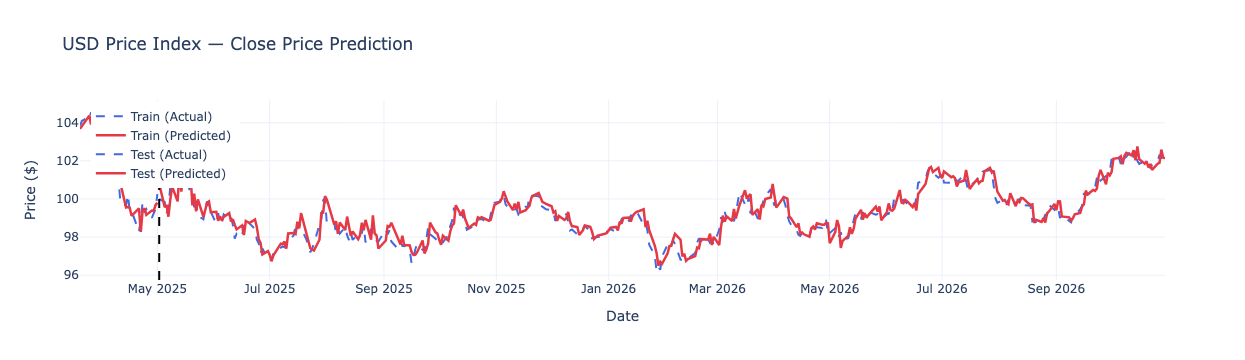

In [13]:
history_size=30

# recalculate the predictions for train and test set
x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)
model = LinearRegression()
model.fit(x_train, y_train)
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)


train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Prediction line for training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train_pred)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='#E63946', width=2.5)
))


# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

# Παρατηρούμε ότι οι προβλέψεις μιμούνται τις πραγματικές τιμές με καθυστέρηση μιας μέρας
fig.show()

# Apply Log Returns Transformation

In [14]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close
0,2021-11-01 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2021-11-02 00:00:00-04:00,-0.002127,-0.001910,-0.000426,0.002234
2,2021-11-03 00:00:00-04:00,0.002021,0.000850,0.000000,-0.002447
3,2021-11-04 00:00:00-04:00,-0.002766,0.002756,0.000107,0.005207
4,2021-11-05 00:00:00-04:00,0.005101,0.001587,0.003829,-0.000318
...,...,...,...,...,...
1252,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
1253,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
1254,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271
1255,2026-10-29 00:00:00-04:00,-0.002837,-0.000390,-0.001962,-0.001469


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [15]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [16]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'CLose-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,CLose-Log-Returns
0,2021-11-01 00:00:00-04:00,93.879997,NaN
1,2021-11-02 00:00:00-04:00,94.089996,0.002234
2,2021-11-03 00:00:00-04:00,93.860001,-0.002447
3,2021-11-04 00:00:00-04:00,94.349998,0.005207
4,2021-11-05 00:00:00-04:00,94.320000,-0.000318
5,2021-11-08 00:00:00-05:00,94.050003,-0.002867


In [17]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

array([94.08999634, 93.86000061, 94.34999847, 94.31999969, 94.05000305])

# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [18]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.006420,True
1,2,0.890831,False
2,3,0.440298,False
3,4,0.919614,False
4,5,0.675700,False
5,6,0.857270,False
6,7,0.963381,False
7,8,0.692352,False
8,9,0.765010,False
9,10,0.759969,False


# Extracting Temporal Features

In [19]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

# Combine US holidays, NYSE holidays, and global events
df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)

df

/var/folders/r9/2w6rqz494j16pn5w9gcnvfrm0000gn/T/ipykernel_4602/3316516892.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6


,Date,Open,High,Low,Close,Month,DayOfWeek,IsHoliday
0,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997,11,0,0
1,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996,11,1,0
2,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001,11,2,0
3,2021-11-04 00:00:00-04:00,93.860001,94.470001,93.830002,94.349998,11,3,0
4,2021-11-05 00:00:00-04:00,94.339996,94.620003,94.190002,94.320000,11,4,0
...,...,...,...,...,...,...,...,...
1252,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999,10,0,0
1253,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000,10,1,0
1254,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002,10,2,0
1255,2026-10-29 00:00:00-04:00,102.080002,102.449997,101.849998,102.040001,10,3,0


In [20]:
df['IsHoliday'].value_counts()

IsHoliday
0    1210
1      47
Name: count, dtype: int64